# Avoiding default legends

In this workbook, I explore data visualizations that eliminate the default legend from a chart. Alternatives to the standard legend are accomplished by directly labeling the visualizations or by faceting to create sub-panels for each category.

In [1]:
from datetime import date
import polars as pl
from plotnine import *

from great_tables import GT

## CPI Index data from the Federal Reserve Bank of St. Louis 

(FRED == Federal Reserve Economic Data)

I'm using data pulled online from FRED. Common categories were chosen for this example. Food, Housing, Apparel, and Medical Care data were retrieved using the "unofficial" API; this allowed me to directly read the CSV files into a data frame for analysis and plotting. 

The raw data was organized as a "long" Polars data frame.

In [2]:
# 1. Define the categories and their FRED IDs
categories = {
    "Food": "CPIFABNS",
    "Housing": "CPIHOSNS",
    "Apparel": "CPIAPPNS",
    # "Transportation": "CPITRNNS", # Exclude as the variation is large.
    "Medical Care": "CPIMEDNS"
}

# 2. Read each series and stack into one long DataFrame
long_df = pl.concat(
    pl.read_csv(
        f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={series_id}",
        null_values=["."],
    ).select(
        pl.col("observation_date").str.to_date(),
        pl.col(series_id).cast(pl.Float64).alias("value"),
        pl.lit(name).alias("category"),
    )
    for name, series_id in categories.items()
).drop_nulls()

# Put every series on a calendar-month grid so shift(12) means 12 months.
# Oct 2025 CPI was never published (government shutdown); it stays a null row.
long_df_monthly = (
    long_df
    .sort("category", "observation_date")
    .upsample(time_column="observation_date", every="1mo", group_by="category", maintain_order=True)
    .with_columns(pl.col("category").forward_fill())
)

In [3]:
long_df

observation_date,value,category
date,f64,str
1967-01-01,34.8,"""Food"""
1967-02-01,34.7,"""Food"""
1967-03-01,34.7,"""Food"""
1967-04-01,34.6,"""Food"""
1967-05-01,34.6,"""Food"""
…,…,…
2026-05-01,593.239,"""Medical Care"""
2026-06-01,592.75,"""Medical Care"""
2026-07-01,593.781,"""Medical Care"""


In [4]:
GT(
    long_df.group_by('category').agg(pl.col('observation_date').min())
        .sort(pl.col('observation_date'))
).cols_label(
    category = 'Category',
    observation_date = 'First observation'
)

Category,First observation
Apparel,1914-12-01
Medical Care,1935-03-01
Housing,1967-01-01
Food,1967-01-01


In [5]:
cpi_wide_df = (
    long_df
    .pivot(on='category', index='observation_date', maintain_order=True)
)

cpi_wide_df.write_csv('cpi_indexs.csv')

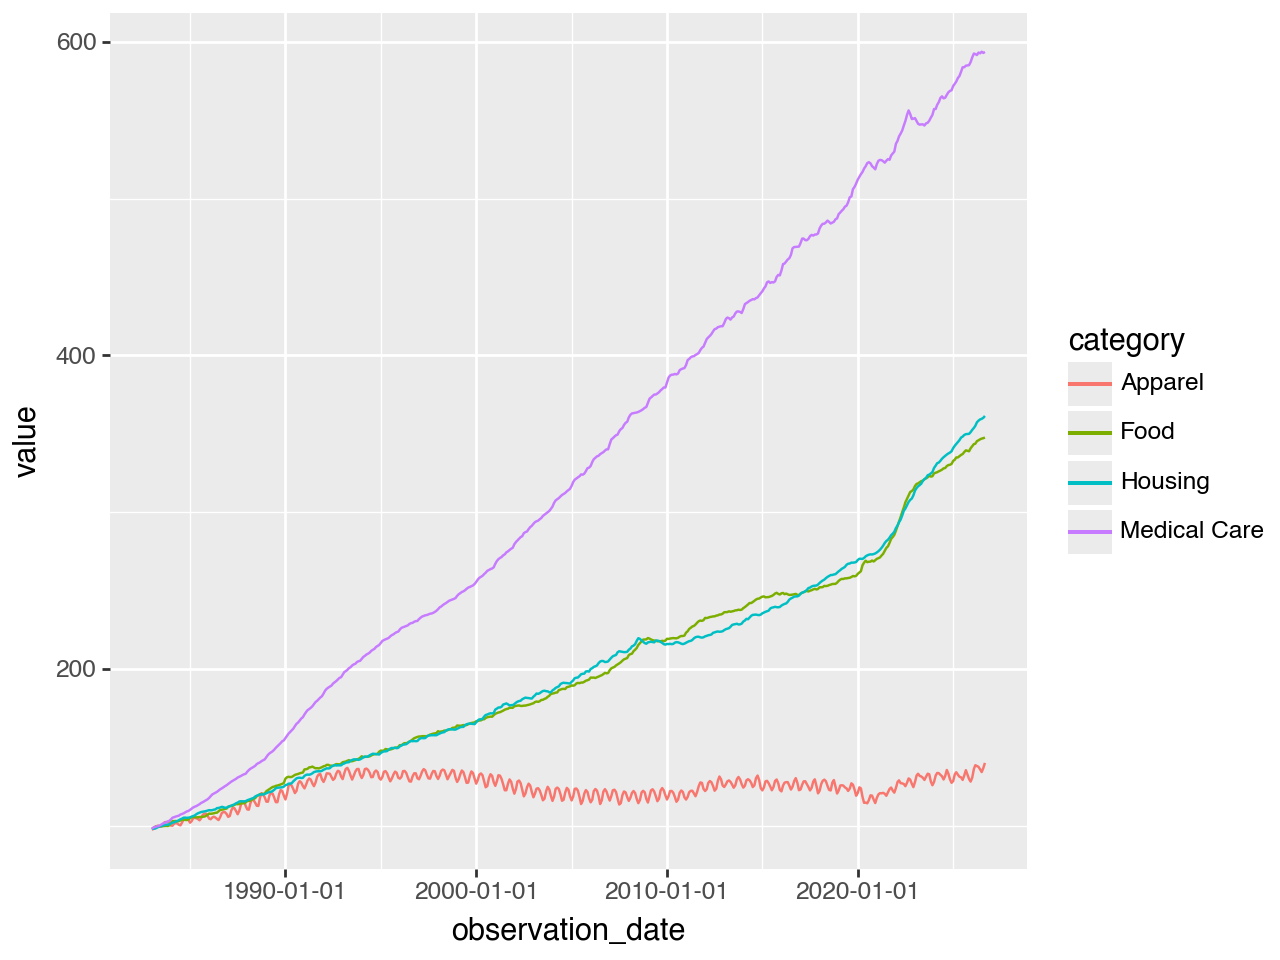

In [6]:
(
    long_df
    .filter(pl.col('observation_date') >= date(1983, 1, 1))
    >>
    ggplot(aes('observation_date', 'value')) 
    + geom_line(aes(color = 'category'))
)

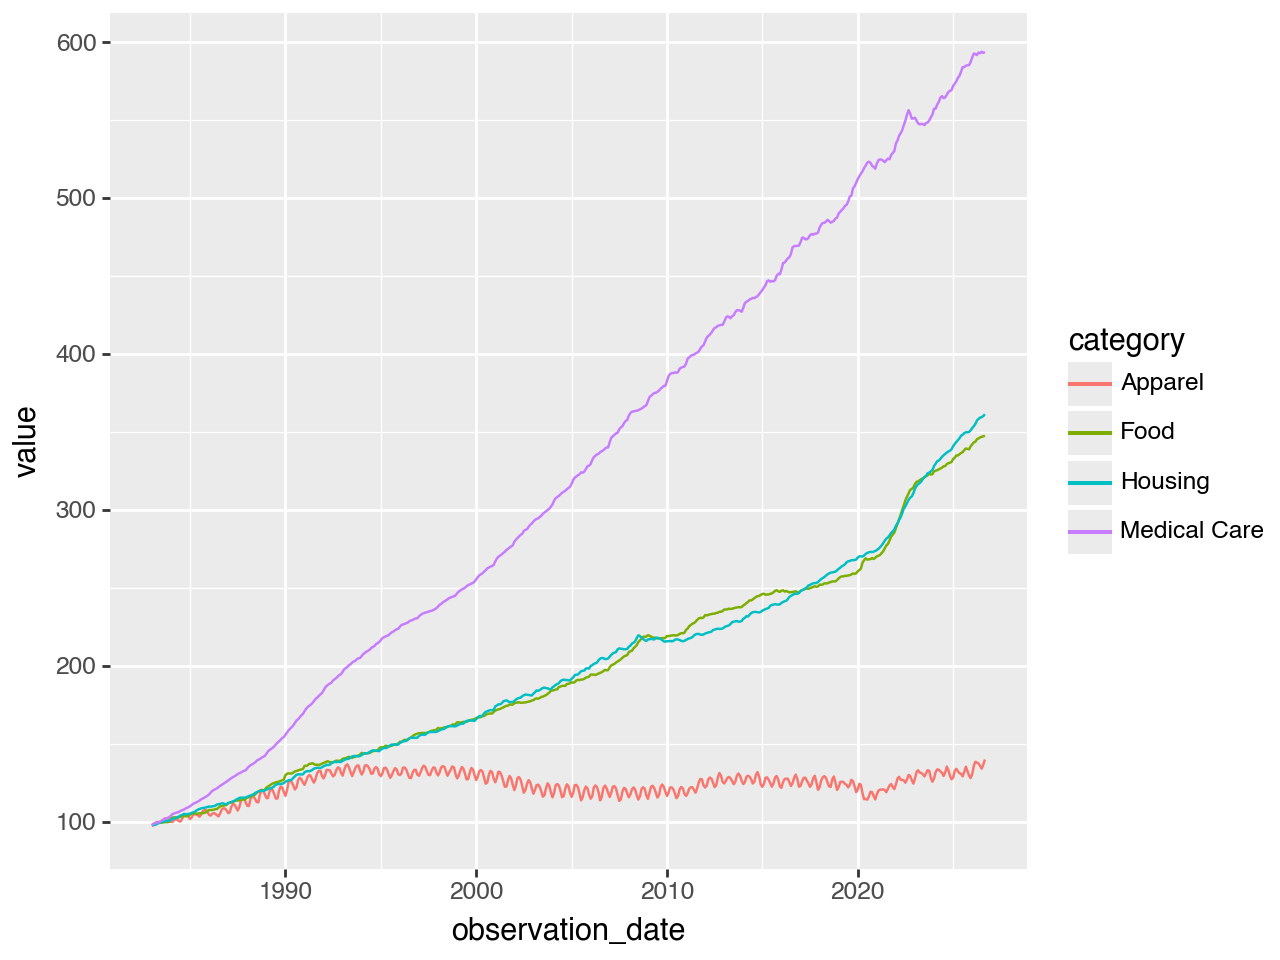

In [7]:
(
    long_df
    .filter(pl.col('observation_date') >= date(1983, 1, 1))
    >>
    ggplot(aes('observation_date', 'value')) 
    + geom_line(aes(color = 'category'))
    + scale_x_date(date_labels='%Y')
    + scale_y_continuous(
        limits=(95, long_df['value'].max()), 
        breaks=pl.linear_space(100, 600, 6, eager=True)
    )
)

## Moving the legend to the top of the chart

This is easily done using the chart's `theme()` layer

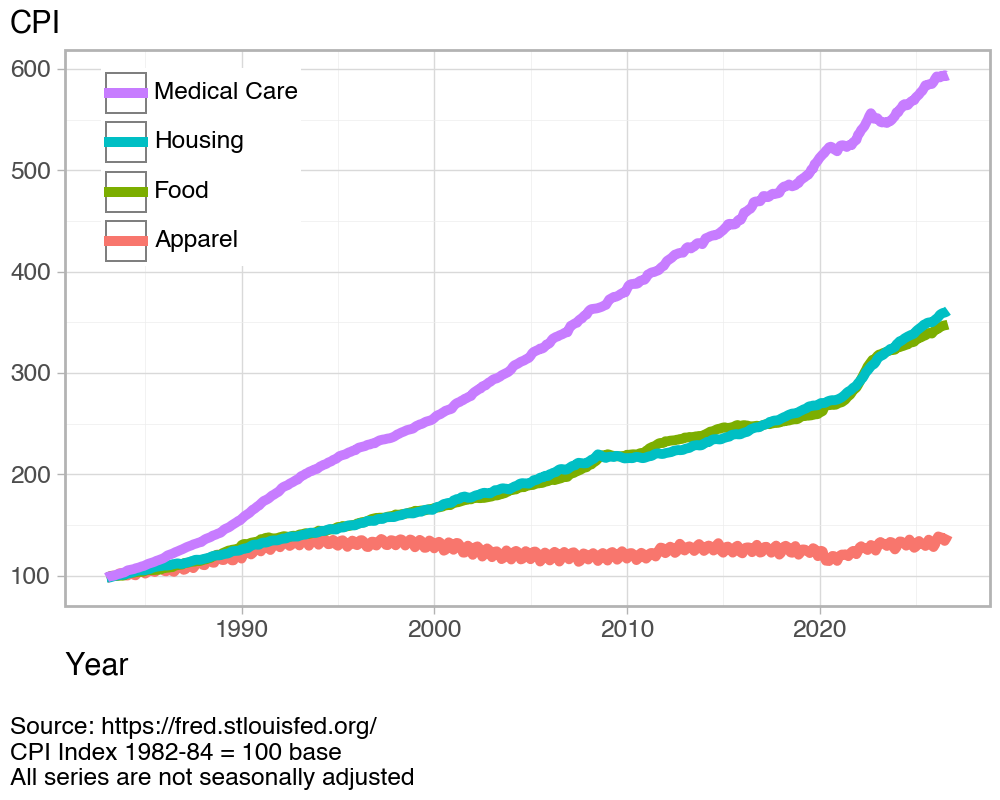

In [8]:
(
    long_df
    .filter(pl.col('observation_date') >= date(1983, 1, 1))
    >>
    ggplot(aes('observation_date', 'value')) 
    + geom_line(aes(color = 'category'), size=2)
    + labs(
        subtitle = 'CPI',
        x = 'Year',
        caption = ('Source: https://fred.stlouisfed.org/ \n'
                   'CPI Index 1982-84 = 100 base \n'
                   'All series are not seasonally adjusted')
    )
    + scale_x_date(date_labels='%Y')
    + scale_y_continuous(
        limits=(95, long_df['value'].max()), 
        breaks=pl.linear_space(100, 600, 6, eager=True)
    )
    + guides(color=guide_legend(reverse=True))
    + theme_light()
    + theme(
        figure_size=(5,4),
        plot_title_position='plot',
        legend_position='inside',
        legend_position_inside=(0.05, 0.95),
        legend_title=element_blank(),
        plot_caption=element_text(
            ha='left', 
            linespacing=1.2, 
            margin={'t':10}),
        plot_caption_position='plot',
        axis_title_x=element_text(ha='left'),
        axis_title_y=element_blank()
    )
)

## Placing the legend on the chart

As an alternative to using a lengend, we can label the data directly on the chart.

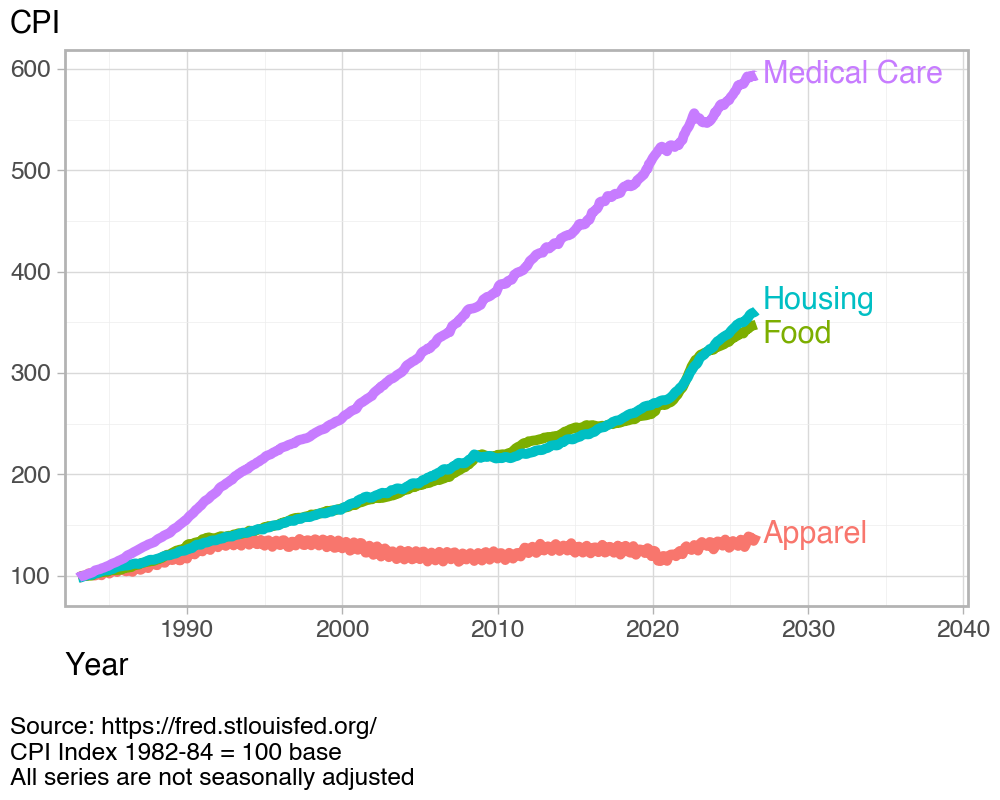

In [9]:
(
    long_df
    .filter(pl.col('observation_date') >= date(1983, 1, 1))
    >>
    ggplot(aes('observation_date', 'value'))
    + geom_line(aes(color='category'), size=2)
    + geom_text(
      aes(y='label_y', label='category', color='category'),
        data=long_df.filter(
            pl.col('observation_date') == pl.col('observation_date').max().over('category'))
            .with_columns(
                (
                    pl.col('value') + pl.col('category').replace_strict(
                    {'Housing': 10, 'Food': -10}, default=0
                    )
                ).alias('label_y')       
            ),
        ha='left',
        nudge_x=150,
    )
    + labs(
        subtitle = 'CPI',
        x = 'Year',
        caption = ('Source: https://fred.stlouisfed.org/ \n'
                   'CPI Index 1982-84 = 100 base \n'
                   'All series are not seasonally adjusted')
    )
    + scale_x_date(date_labels='%Y', expand=(0.02, 0, 0.3, 0))
    + scale_y_continuous(
      limits=(95, long_df['value'].max()),
      breaks=pl.linear_space(100, 600, 6, eager=True),
    )
    + theme_light()
    + theme(
        figure_size=(5, 4),
        plot_title_position='plot',
        legend_position='none',
        plot_caption=element_text(
            ha='left', 
            linespacing=1.2, 
            margin={'t':10}),
        plot_caption_position='plot',
        axis_title_x=element_text(ha='left'),
        axis_title_y=element_blank()
           )
)

### Compute YoY in long format

Compute YoY in long format with `shift(12).over("category")` on the calendar-month grid, keeping each category's full history.

In [10]:
cpi_yoy_long_over = (
    long_df_monthly
    .with_columns(
        yoy_pct=(pl.col('value') / pl.col('value').shift(12).over('category') - 1) * 100
    )
    .drop_nulls('yoy_pct')
    .select('observation_date', 'category', 'yoy_pct')
)
cpi_yoy_long_over

observation_date,category,yoy_pct
date,str,f64
1915-12-01,"""Apparel""",4.0
1916-12-01,"""Apparel""",14.74359
1917-12-01,"""Apparel""",24.022346
1918-12-01,"""Apparel""",43.243243
1919-12-01,"""Apparel""",33.962264
…,…,…
2026-05-01,"""Medical Care""",2.592131
2026-06-01,"""Medical Care""",2.026239
2026-07-01,"""Medical Care""",1.699905


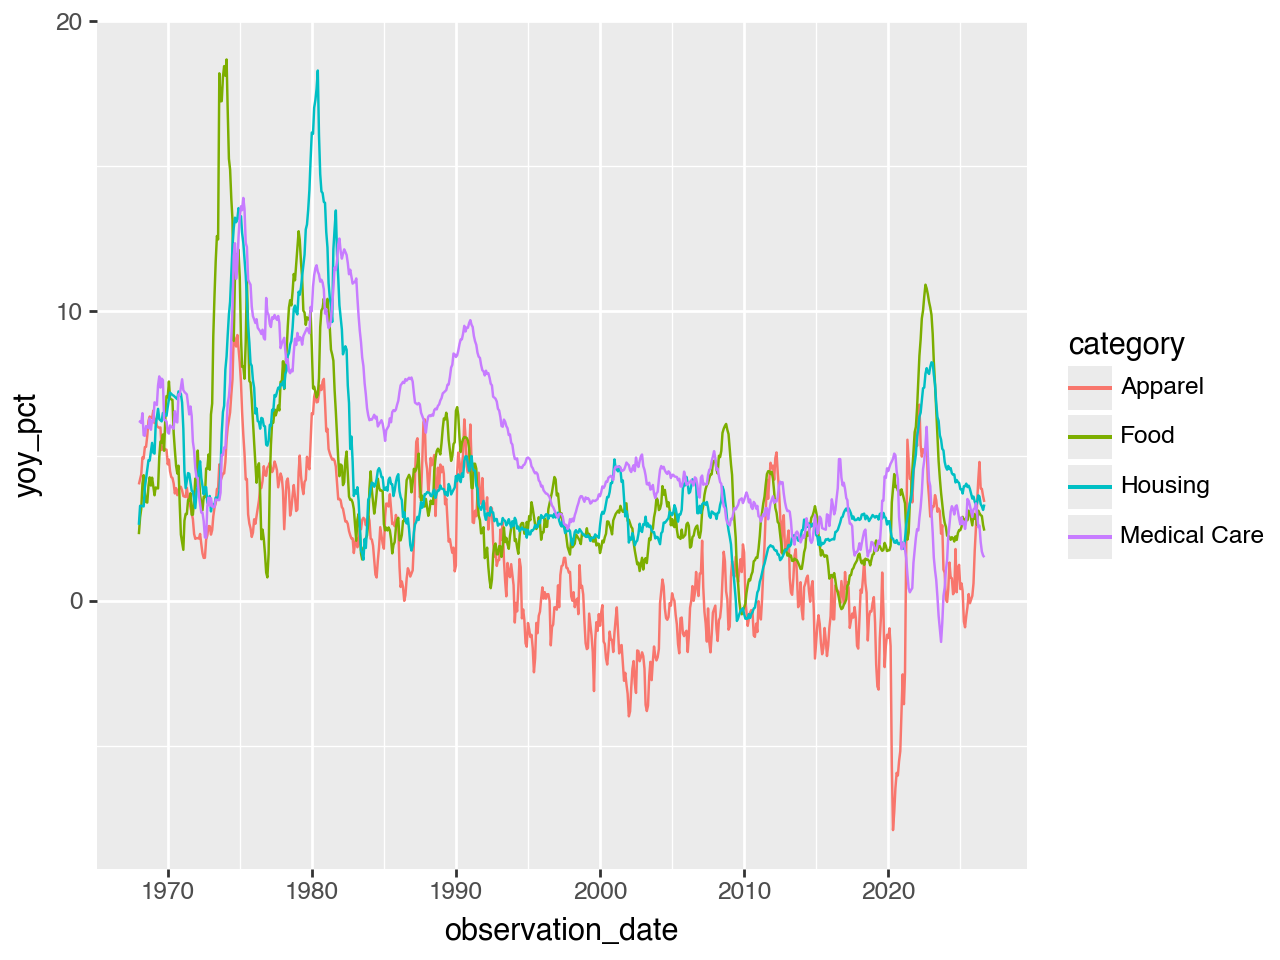

In [11]:
(
    cpi_yoy_long_over
    .filter(pl.col('observation_date') >= date(1968, 1, 1))
    >>
    ggplot(aes('observation_date', 'yoy_pct')) +
    geom_line(aes(color = 'category')) +
    scale_x_date(date_breaks='10 years', date_labels='%Y')
)

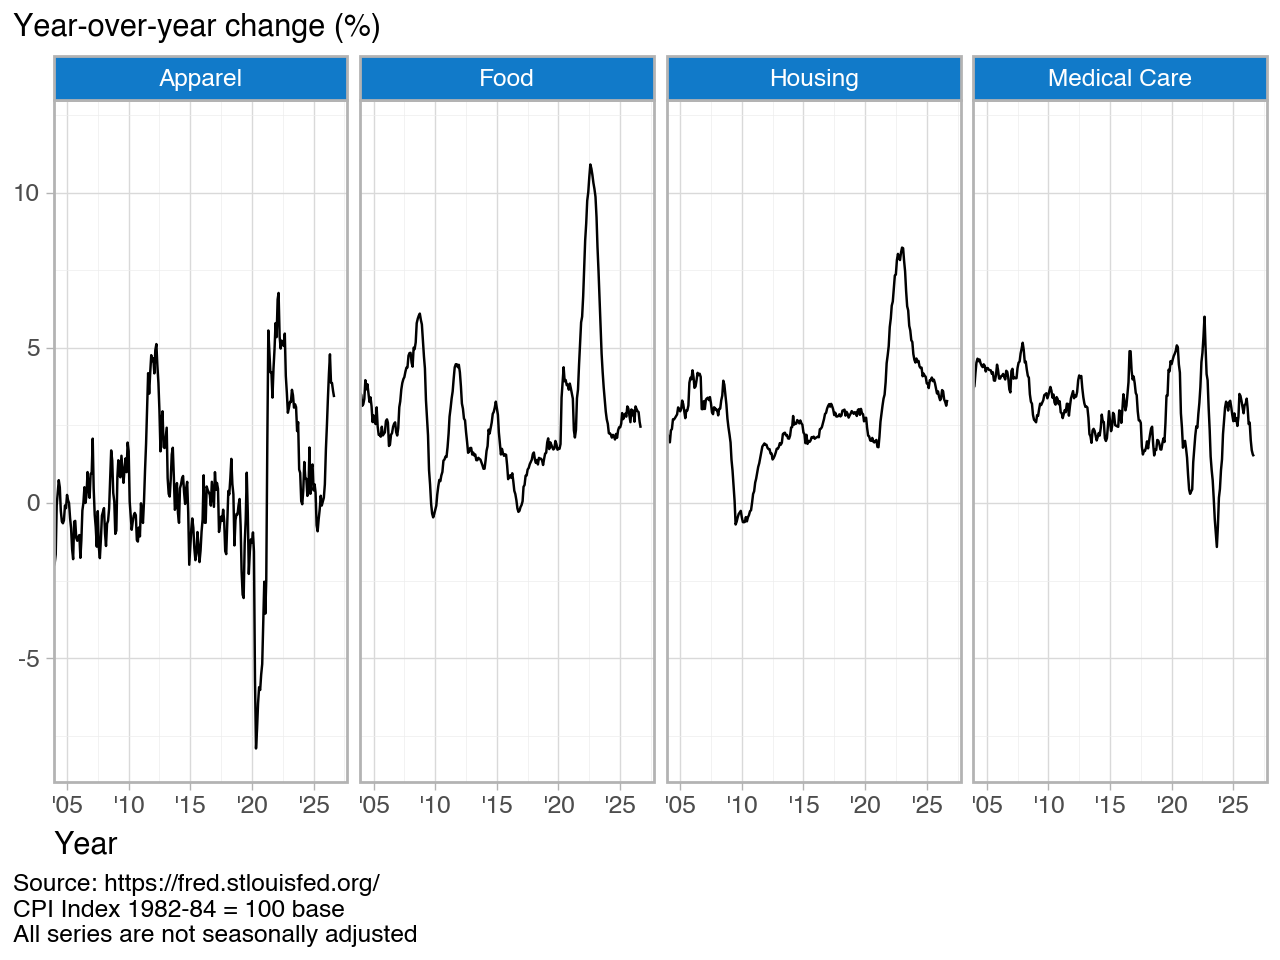

In [12]:
cpi_yoy_chart = (cpi_yoy_long_over
    >>
    ggplot(aes('observation_date', 'yoy_pct'))
    + geom_line()
    + labs(
        x = 'Year',
        subtitle = 'Year-over-year change (%)',
        caption = ('Source: https://fred.stlouisfed.org/ \n'
                   'CPI Index 1982-84 = 100 base \n'
                   'All series are not seasonally adjusted')
    )
    + scale_x_date(date_breaks='5 years', date_labels="'%y")
    + coord_cartesian(
        xlim = (
            date(2005, 1, 1), cpi_yoy_long_over['observation_date'].max()
        ),
        ylim = (-8, 12)
    )
    + facet_wrap('category', ncol=4)
    + theme_light()
    + theme(
        plot_caption_position='plot',
        axis_title_x=element_text(ha=0),
        axis_title_y=element_blank(),
        plot_title_position='plot',
        plot_caption=element_text(linespacing=1.2, ha='left'),
        strip_background=element_rect(fill="#117ac9")
    )
)

cpi_yoy_chart

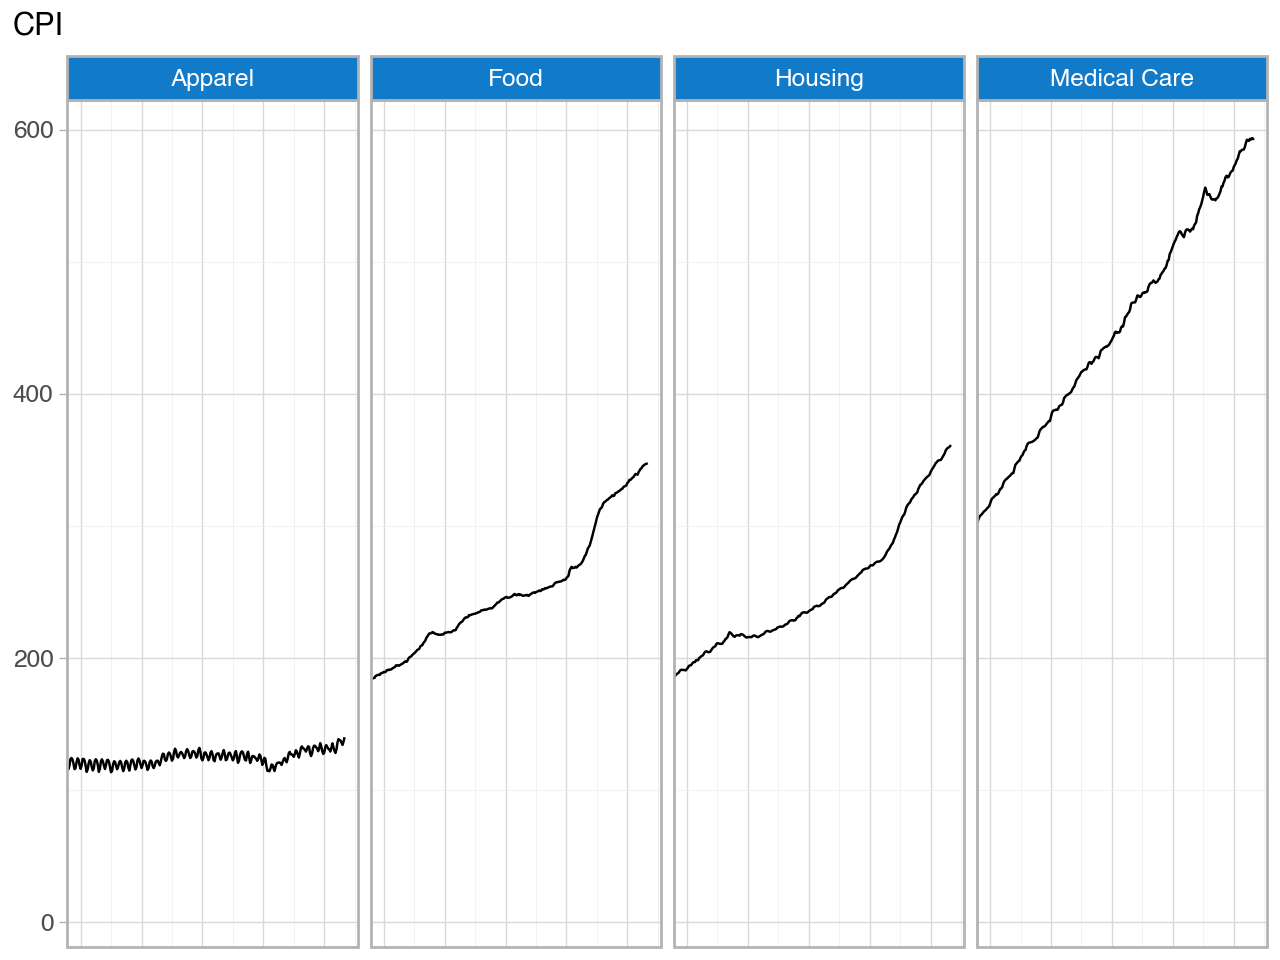

In [13]:
cpi_values_chart = (long_df
    >>
    ggplot(aes('observation_date', 'value'))
    + geom_line()
    + labs(
        subtitle = 'CPI'
    )
    + scale_x_date(date_breaks='5 years', date_labels="'%y")
    + coord_cartesian(
        xlim = (
            date(2005, 1, 1), long_df['observation_date'].max()
        )
    )
    + facet_wrap('category', ncol=4)
    + theme_light()
    + theme(
        plot_title_position='plot',
        axis_title_x=element_blank(),
        axis_text_x=element_blank(),
        axis_ticks_major_x=element_blank(),
        axis_title_y=element_blank(),
        strip_background=element_rect(fill = "#117ac9")
    )
)

cpi_values_chart

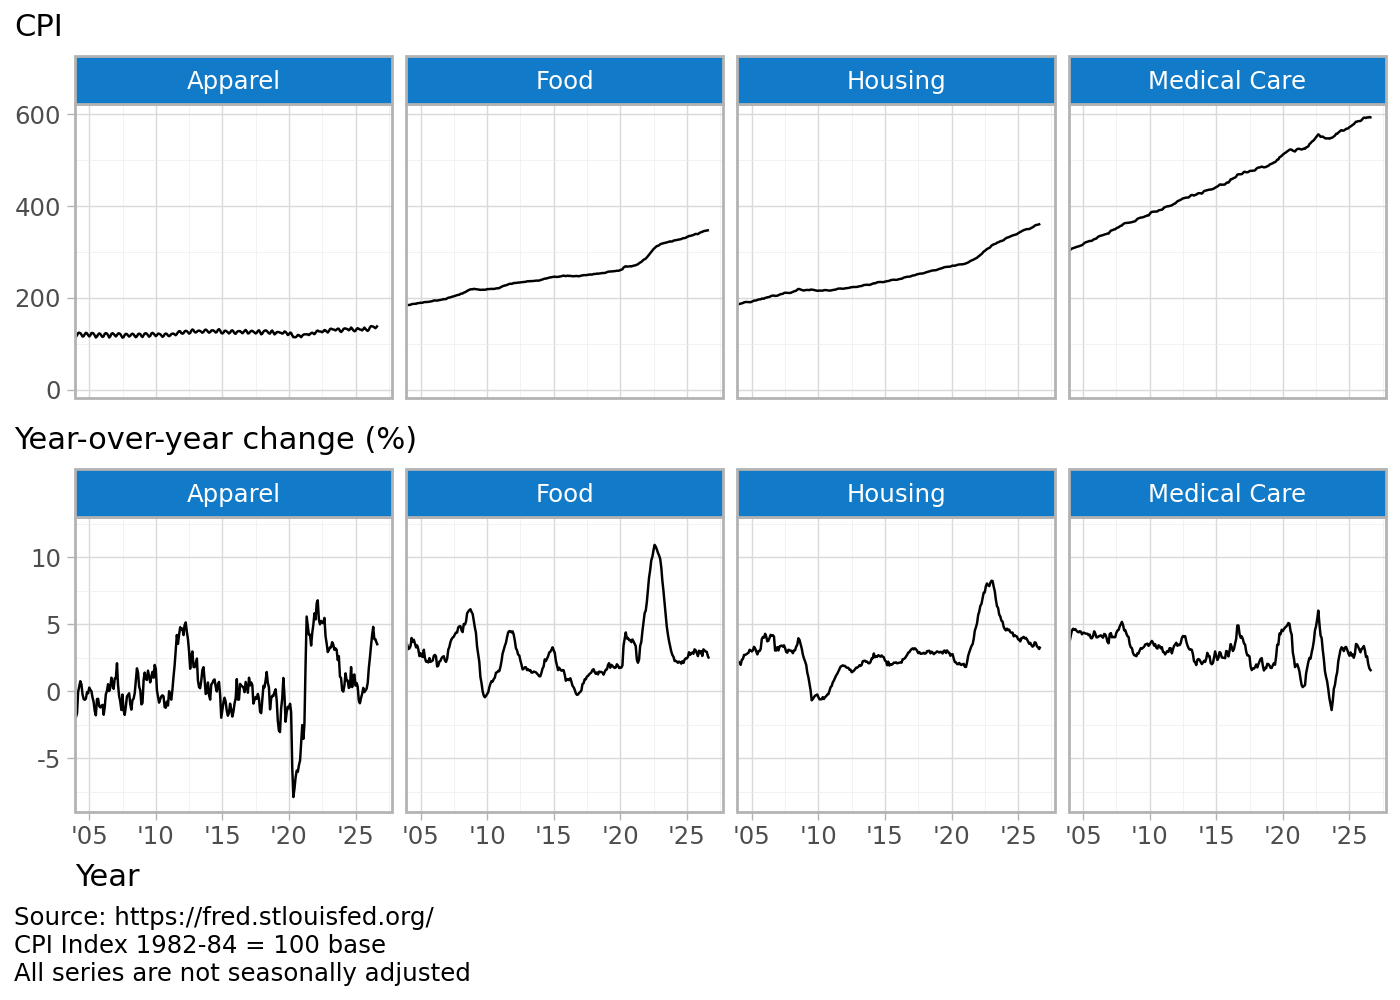

In [14]:
(
    (cpi_values_chart / cpi_yoy_chart ) + theme(figure_size=(7, 5))
) 